# Niave Bayes

In machine learning, Naïve Bayes classification is a straightforward and powerful algorithm for the classification task. Naïve Bayes classification is based on applying Bayes’ theorem with strong independence assumption between the features. Naïve Bayes classification produces good results when we use it for textual data analysis such as Natural Language Processing.

#### Types of Naive Bayes algorithm

### 1. Gaussian Naïve Bayes algorithm 


When we have continuous attribute values, we made an assumption that the values associated with each class are distributed according to Gaussian or Normal distribution. For example, suppose the training data contains a continuous attribute x. We first segment the data by the class, and then compute the mean and variance of x in each class. Let µi be the mean of the values and let σi be the variance of the values associated with the ith class. Suppose we have some observation value xi

### 2. Multinomial Naïve Bayes algorithm

With a Multinomial Naïve Bayes model, samples (feature vectors) represent the frequencies with which certain events have been generated by a multinomial (p1, . . . ,pn) where pi is the probability that event i occurs. Multinomial Naïve Bayes algorithm is preferred to use on data that is multinomially distributed. It is one of the standard algorithms which is used in text categorization classification.



### 3. Bernoulli Naïve Bayes algorithm

In the multivariate Bernoulli event model, features are independent boolean variables (binary variables) describing inputs. Just like the multinomial model, this model is also popular for document classification tasks where binary term occurrence features are used rather than term frequencies.

### Import Libraries

In [692]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
import category_encoders as ce
from sklearn.preprocessing import RobustScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay



### Reading Data

In [644]:
df = pd.read_csv("E:/Machine Learning/Datasets/adult.csv")

### Exploratory data analysis

In [645]:
df.head()

,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
0,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
1,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
2,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
3,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K
4,37,Private,284582,Masters,14,Married-civ-spouse,Exec-managerial,Wife,White,Female,0,0,40,United-States,<=50K


In [646]:
col_names = ['age', 'workclass', 'fnlwgt', 'education', 'education_num', 'marital_status', 'occupation', 'relationship',
             'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income']
df.columns = col_names

df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education_num',
       'marital_status', 'occupation', 'relationship', 'race', 'sex',
       'capital_gain', 'capital_loss', 'hours_per_week', 'native_country',
       'income'],
      dtype='str')

In [647]:
df.shape

(32560, 15)

In [648]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32560 entries, 0 to 32559
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32560 non-null  int64
 1   workclass       32560 non-null  str  
 2   fnlwgt          32560 non-null  int64
 3   education       32560 non-null  str  
 4   education_num   32560 non-null  int64
 5   marital_status  32560 non-null  str  
 6   occupation      32560 non-null  str  
 7   relationship    32560 non-null  str  
 8   race            32560 non-null  str  
 9   sex             32560 non-null  str  
 10  capital_gain    32560 non-null  int64
 11  capital_loss    32560 non-null  int64
 12  hours_per_week  32560 non-null  int64
 13  native_country  32560 non-null  str  
 14  income          32560 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.7 MB


### Explore Categorical Variables

In [649]:
categorical = df.select_dtypes(include=['object']).columns

print('There are {} categorical variables\n'.format(len(categorical)))
print('The categorical variables are :\n\n', categorical)

There are 9 categorical variables

The categorical variables are :

 Index(['workclass', 'education', 'marital_status', 'occupation',
       'relationship', 'race', 'sex', 'native_country', 'income'],
      dtype='str')


C:\Users\moham\AppData\Local\Temp\ipykernel_33268\2200463973.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = df.select_dtypes(include=['object']).columns


In [650]:
df[categorical].head()

,workclass,education,marital_status,occupation,relationship,race,sex,native_country,income
0,Self-emp-not-inc,Bachelors,Married-civ-spouse,Exec-managerial,Husband,White,Male,United-States,<=50K
1,Private,HS-grad,Divorced,Handlers-cleaners,Not-in-family,White,Male,United-States,<=50K
2,Private,11th,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,United-States,<=50K
3,Private,Bachelors,Married-civ-spouse,Prof-specialty,Wife,Black,Female,Cuba,<=50K
4,Private,Masters,Married-civ-spouse,Exec-managerial,Wife,White,Female,United-States,<=50K


### EDA With Categorical Variables

In [651]:
df[categorical].isnull().sum()

workclass         0
education         0
marital_status    0
occupation        0
relationship      0
race              0
sex               0
native_country    0
income            0
dtype: int64

In [652]:
for var in categorical:
    print(f"{var} : {df[var].value_counts()}")

workclass : workclass
Private             22696
Self-emp-not-inc     2541
Local-gov            2093
?                    1836
State-gov            1297
Self-emp-inc         1116
Federal-gov           960
Without-pay            14
Never-worked            7
Name: count, dtype: int64
education : education
HS-grad         10501
Some-college     7291
Bachelors        5354
Masters          1723
Assoc-voc        1382
11th             1175
Assoc-acdm       1067
10th              933
7th-8th           646
Prof-school       576
9th               514
12th              433
Doctorate         413
5th-6th           333
1st-4th           168
Preschool          51
Name: count, dtype: int64
marital_status : marital_status
Married-civ-spouse       14976
Never-married            10682
Divorced                  4443
Separated                 1025
Widowed                    993
Married-spouse-absent      418
Married-AF-spouse           23
Name: count, dtype: int64
occupation : occupation
Prof-specialty     

### Explore Workclass Variable

In [653]:
df['workclass'].value_counts()

workclass
Private             22696
Self-emp-not-inc     2541
Local-gov            2093
?                    1836
State-gov            1297
Self-emp-inc         1116
Federal-gov           960
Without-pay            14
Never-worked            7
Name: count, dtype: int64

In [654]:
df['workclass'].unique()

<StringArray>
[' Self-emp-not-inc',          ' Private',        ' State-gov',
      ' Federal-gov',        ' Local-gov',                ' ?',
     ' Self-emp-inc',      ' Without-pay',     ' Never-worked']
Length: 9, dtype: str

In [655]:
df['workclass'] = df['workclass'].replace(' ?', np.nan, inplace=True)

C:\Users\moham\AppData\Local\Temp\ipykernel_33268\1536418053.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['workclass'] = df['workclass'].replace(' ?', np.nan, inplace=True)


In [656]:
df['workclass'].value_counts()

workclass
Private             22696
Self-emp-not-inc     2541
Local-gov            2093
State-gov            1297
Self-emp-inc         1116
Federal-gov           960
Without-pay            14
Never-worked            7
Name: count, dtype: int64

### Explore occupation Variable

In [657]:
df['occupation'].value_counts()

occupation
Prof-specialty       4140
Craft-repair         4099
Exec-managerial      4066
Adm-clerical         3769
Sales                3650
Other-service        3295
Machine-op-inspct    2002
?                    1843
Transport-moving     1597
Handlers-cleaners    1370
Farming-fishing       994
Tech-support          928
Protective-serv       649
Priv-house-serv       149
Armed-Forces            9
Name: count, dtype: int64

In [658]:
df['occupation'].unique()

<StringArray>
[  ' Exec-managerial', ' Handlers-cleaners',    ' Prof-specialty',
     ' Other-service',      ' Adm-clerical',             ' Sales',
      ' Craft-repair',  ' Transport-moving',   ' Farming-fishing',
 ' Machine-op-inspct',      ' Tech-support',                 ' ?',
   ' Protective-serv',      ' Armed-Forces',   ' Priv-house-serv']
Length: 15, dtype: str

In [659]:
df['occupation'] = df['occupation'].replace(' ?', np.nan, inplace=True)

C:\Users\moham\AppData\Local\Temp\ipykernel_33268\148225010.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['occupation'] = df['occupation'].replace(' ?', np.nan, inplace=True)


In [660]:
df['occupation'].value_counts()

occupation
Prof-specialty       4140
Craft-repair         4099
Exec-managerial      4066
Adm-clerical         3769
Sales                3650
Other-service        3295
Machine-op-inspct    2002
Transport-moving     1597
Handlers-cleaners    1370
Farming-fishing       994
Tech-support          928
Protective-serv       649
Priv-house-serv       149
Armed-Forces            9
Name: count, dtype: int64

### Explore native_country Variable

In [661]:
df['native_country'].value_counts()

native_country
United-States                 29169
Mexico                          643
?                               583
Philippines                     198
Germany                         137
Canada                          121
Puerto-Rico                     114
El-Salvador                     106
India                           100
Cuba                             95
England                          90
Jamaica                          81
South                            80
China                            75
Italy                            73
Dominican-Republic               70
Vietnam                          67
Guatemala                        64
Japan                            62
Poland                           60
Columbia                         59
Taiwan                           51
Haiti                            44
Iran                             43
Portugal                         37
Nicaragua                        34
Peru                             31
France       

In [662]:
df['native_country'].unique()

<StringArray>
[             ' United-States',                       ' Cuba',
                    ' Jamaica',                      ' India',
                          ' ?',                     ' Mexico',
                      ' South',                ' Puerto-Rico',
                   ' Honduras',                    ' England',
                     ' Canada',                    ' Germany',
                       ' Iran',                ' Philippines',
                      ' Italy',                     ' Poland',
                   ' Columbia',                   ' Cambodia',
                   ' Thailand',                    ' Ecuador',
                       ' Laos',                     ' Taiwan',
                      ' Haiti',                   ' Portugal',
         ' Dominican-Republic',                ' El-Salvador',
                     ' France',                  ' Guatemala',
                      ' China',                      ' Japan',
                 ' Yugoslavia',          

In [663]:
df['native_country'] = df['native_country'].replace(' ?', np.nan, inplace=True)

C:\Users\moham\AppData\Local\Temp\ipykernel_33268\700092599.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['native_country'] = df['native_country'].replace(' ?', np.nan, inplace=True)


In [664]:
df['native_country'].value_counts()

native_country
United-States                 29169
Mexico                          643
Philippines                     198
Germany                         137
Canada                          121
Puerto-Rico                     114
El-Salvador                     106
India                           100
Cuba                             95
England                          90
Jamaica                          81
South                            80
China                            75
Italy                            73
Dominican-Republic               70
Vietnam                          67
Guatemala                        64
Japan                            62
Poland                           60
Columbia                         59
Taiwan                           51
Haiti                            44
Iran                             43
Portugal                         37
Nicaragua                        34
Peru                             31
France                           29
Greece       

### Check Missing values in Categorical Variables Again

In [665]:
df[categorical].isnull().sum()



workclass         1836
education            0
marital_status       0
occupation        1843
relationship         0
race                 0
sex                  0
native_country     583
income               0
dtype: int64

### Explore Number of Labels

In [666]:
for var in categorical:
    print(var, ' contains ', len(df[var].unique()), ' labels')

workclass  contains  9  labels
education  contains  16  labels
marital_status  contains  7  labels
occupation  contains  15  labels
relationship  contains  6  labels
race  contains  5  labels
sex  contains  2  labels
native_country  contains  42  labels
income  contains  2  labels


### Explore Numerical Variables

In [667]:
numerical = df.select_dtypes(include=['int64']).columns

In [668]:
df[numerical].head()

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
0,50,83311,13,0,0,13
1,38,215646,9,0,0,40
2,53,234721,7,0,0,40
3,28,338409,13,0,0,40
4,37,284582,14,0,0,40


### Explore Problems with Numerical variables

In [669]:
df[numerical].isnull().sum()

age               0
fnlwgt            0
education_num     0
capital_gain      0
capital_loss      0
hours_per_week    0
dtype: int64

### Declare feature vector and target variable

In [670]:
x = df.drop('income', axis=1)

y = df['income']

### Split data into separate training and test set

In [671]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0)

In [672]:
x_train.shape, x_test.shape


((26048, 14), (6512, 14))

### Feature Engineering

In [673]:
x_train.dtypes

age               int64
workclass           str
fnlwgt            int64
education           str
education_num     int64
marital_status      str
occupation          str
relationship        str
race                str
sex                 str
capital_gain      int64
capital_loss      int64
hours_per_week    int64
native_country      str
dtype: object

In [674]:
categorical = x_train.select_dtypes(include=['object']).columns
categorical

C:\Users\moham\AppData\Local\Temp\ipykernel_33268\3727764399.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = x_train.select_dtypes(include=['object']).columns


Index(['workclass', 'education', 'marital_status', 'occupation',
       'relationship', 'race', 'sex', 'native_country'],
      dtype='str')

In [675]:
numerical = df.select_dtypes(include=['int64']).columns
numerical

Index(['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss',
       'hours_per_week'],
      dtype='str')

### Engineering missing values in categorical variables


In [676]:
x_train[categorical].isnull().sum()

workclass         1479
education            0
marital_status       0
occupation        1484
relationship         0
race                 0
sex                  0
native_country     464
dtype: int64

In [677]:
for col in categorical:
    if x_train[col].isnull().mean() > 0:
        print(col, x_train[col].isnull().mean())

workclass 0.056779791154791155
occupation 0.056971744471744475
native_country 0.017813267813267815


In [678]:
for col in ['workclass', 'occupation', 'native_country']:
    mode_value = x_train[col].mode()[0]

    x_train[col] = x_train[col].fillna(mode_value)
    x_test[col] = x_test[col].fillna(mode_value)

In [679]:
x_train[categorical].isnull().sum()

workclass         0
education         0
marital_status    0
occupation        0
relationship      0
race              0
sex               0
native_country    0
dtype: int64

In [680]:
x_train.isnull().sum()

age               0
workclass         0
fnlwgt            0
education         0
education_num     0
marital_status    0
occupation        0
relationship      0
race              0
sex               0
capital_gain      0
capital_loss      0
hours_per_week    0
native_country    0
dtype: int64

In [681]:
x_test.isnull().sum()

age               0
workclass         0
fnlwgt            0
education         0
education_num     0
marital_status    0
occupation        0
relationship      0
race              0
sex               0
capital_gain      0
capital_loss      0
hours_per_week    0
native_country    0
dtype: int64

### Encode categorical variables

In [682]:
categorical

Index(['workclass', 'education', 'marital_status', 'occupation',
       'relationship', 'race', 'sex', 'native_country'],
      dtype='str')

In [683]:
x_train[categorical].head()

,workclass,education,marital_status,occupation,relationship,race,sex,native_country
12467,Private,Bachelors,Married-civ-spouse,Exec-managerial,Husband,White,Male,United-States
15282,Self-emp-not-inc,Bachelors,Married-civ-spouse,Farming-fishing,Husband,White,Male,United-States
24869,Private,HS-grad,Never-married,Exec-managerial,Not-in-family,White,Female,United-States
18822,Private,7th-8th,Divorced,Handlers-cleaners,Not-in-family,White,Male,United-States
26403,Private,HS-grad,Married-civ-spouse,Sales,Wife,Black,Female,United-States


In [684]:
encoder = ce.OneHotEncoder(cols=['workclass', 'education', 'marital_status', 'occupation', 
                                  'relationship', 'race', 'sex', 'native_country'])

x_train = encoder.fit_transform(x_train)
x_test = encoder.transform(x_test)

In [685]:
x_train.head()

,age,workclass_1,workclass_2,workclass_3,workclass_4,workclass_5,workclass_6,workclass_7,workclass_8,fnlwgt,...,native_country_32,native_country_33,native_country_34,native_country_35,native_country_36,native_country_37,native_country_38,native_country_39,native_country_40,native_country_41
12467,34,1,0,0,0,0,0,0,0,117444,...,0,0,0,0,0,0,0,0,0,0
15282,54,0,1,0,0,0,0,0,0,109413,...,0,0,0,0,0,0,0,0,0,0
24869,35,1,0,0,0,0,0,0,0,198202,...,0,0,0,0,0,0,0,0,0,0
18822,33,1,0,0,0,0,0,0,0,190511,...,0,0,0,0,0,0,0,0,0,0
26403,50,1,0,0,0,0,0,0,0,138270,...,0,0,0,0,0,0,0,0,0,0


In [686]:
x_train.shape

(26048, 105)

### Feature Scaling

In [687]:
scaler = RobustScaler()

x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [688]:
x_train

array([[-0.15,  0.  ,  0.  , ...,  0.  ,  0.  ,  0.  ],
       [ 0.85, -1.  ,  1.  , ...,  0.  ,  0.  ,  0.  ],
       [-0.1 ,  0.  ,  0.  , ...,  0.  ,  0.  ,  0.  ],
       ...,
       [ 0.3 , -1.  ,  1.  , ...,  0.  ,  0.  ,  0.  ],
       [-0.8 , -1.  ,  0.  , ...,  0.  ,  0.  ,  0.  ],
       [ 0.6 , -1.  ,  0.  , ...,  0.  ,  0.  ,  0.  ]],
      shape=(26048, 105))

### Train The Model

In [689]:
model = GaussianNB()

model.fit(x_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[19762., 6286.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.76,0.24]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[<U6](2,)","[' <=50K',' >50K']"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,0.05587
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,105
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 105)","[[-0.01,-0.22, 0.07,..., 0. , 0. , 0. ], [ 0.36,-0.35, 0.09,..., 0. , 0. , 0. ]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 105)","[[0.54,0.22,0.12,...,0.06,0.06,0.06], [0.34,0.28,0.14,...,0.06,0.06,0.06]]"


### Prediction

In [690]:
y_pred = model.predict(x_test)

### Check accuracy score

In [691]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.8137285012285013
              precision    recall  f1-score   support

       <=50K       0.93      0.82      0.87      4957
        >50K       0.58      0.80      0.67      1555

    accuracy                           0.81      6512
   macro avg       0.75      0.81      0.77      6512
weighted avg       0.85      0.81      0.82      6512



### Confusion Matrix

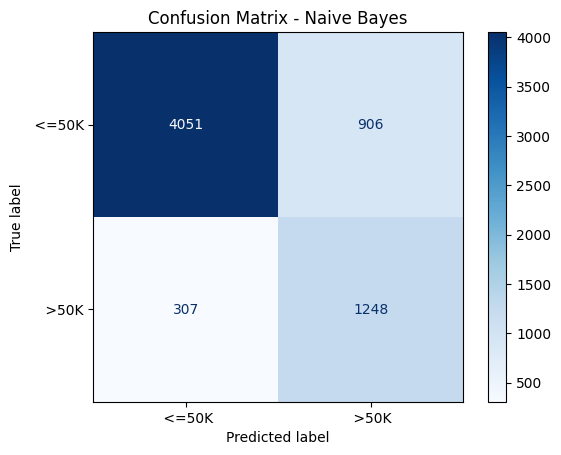

In [ ]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Naive Bayes')
plt.show()

### 

### Conclusion

In this project, I used the Naive Bayes algorithm to predict whether an individual's annual income exceeds $50K based on census data.

After preprocessing the dataset and encoding categorical features using One-Hot Encoding, the model achieved an accuracy of 81.37%.

The model achieved a recall of 80% and an F1-score of 0.67 for the >50K class, showing a reasonable ability to identify individuals with higher incomes. However, the precision for this class was 58%, indicating that some predictions were incorrect.

Overall, this project demonstrated the importance of data preprocessing, categorical encoding, and evaluating classification models using multiple metrics rather than accuracy alone. Further improvements could focus on reducing false positives and achieving a better balance between precision and recall.